In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import torch

# Project paths
PROJECT_DIR = Path(r"E:\SAM")
DATA_DIR = PROJECT_DIR / "data"
MANIFEST_DIR = PROJECT_DIR / "manifests"
OUTPUT_DIR = PROJECT_DIR / "outputs"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"

# Create output directories if needed
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset files
TRAIN_CSV = DATA_DIR / "train.csv"
TRAIN_IMAGES_DIR = DATA_DIR / "train_images"

# Existing split manifest
SPLIT_MANIFEST = MANIFEST_DIR / "split_manifest_v2.json"

# Verify required paths
required_paths = {
    "Project directory": PROJECT_DIR,
    "Training CSV": TRAIN_CSV,
    "Training images": TRAIN_IMAGES_DIR,
    "Split manifest": SPLIT_MANIFEST,
}

for name, path in required_paths.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")
    print(f"  {path}")

assert all(path.exists() for path in required_paths.values()), (
    "A required path is missing. Fix the path before continuing."
)

# Load manifest and annotations
with open(SPLIT_MANIFEST, "r", encoding="utf-8") as f:
    manifest = json.load(f)

df = pd.read_csv(TRAIN_CSV)

S1 = manifest["splits"]["S1"]
DEV = manifest["splits"]["dev"]

print("\n--- Dataset ---")
print("CSV records:", len(df))
print("Unique annotated images:", df["ImageId"].nunique())
print("Training images on disk:", len(list(TRAIN_IMAGES_DIR.glob("*.jpg"))))

print("\n--- Splits ---")
print("S1 training images:", len(S1))
print("Development images:", len(DEV))

print("\n--- Environment ---")
print("Python/PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

Project directory: FOUND
  E:\SAM
Training CSV: FOUND
  E:\SAM\data\train.csv
Training images: FOUND
  E:\SAM\data\train_images
Split manifest: FOUND
  E:\SAM\manifests\split_manifest_v2.json

--- Dataset ---
CSV records: 7095
Unique annotated images: 6666
Training images on disk: 12568

--- Splits ---
S1 training images: 50
Development images: 200

--- Environment ---
Python/PyTorch: 2.14.1+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4070 Ti SUPER


Image ID: 06ad83bac.jpg
Image shape: (256, 1600, 3)
Mask shape: (256, 1600)
Mask values: [0 1]
Defect pixels: 105296


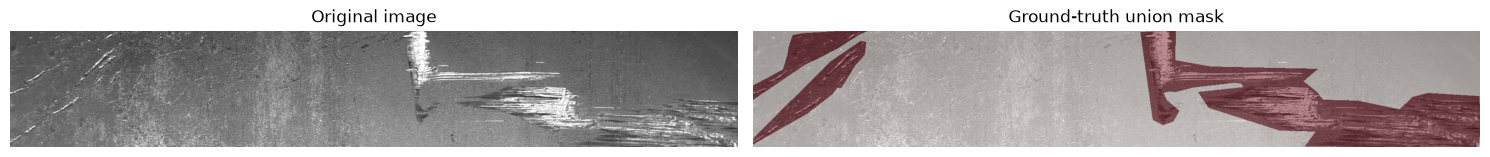

In [2]:

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# Map each image to its annotation rows.
rles_by_image = (
    df.groupby("ImageId")["EncodedPixels"]
      .apply(list)
      .to_dict()
)

def decode_rle(encoded_pixels, height=256, width=1600):
    """Decode the dataset's 1-indexed, column-major RLE."""
    values = np.asarray(
        [int(v) for v in encoded_pixels.split()],
        dtype=np.int64,
    )

    if len(values) == 0 or len(values) % 2 != 0:
        raise ValueError("Empty or malformed RLE")

    starts = values[0::2] - 1
    lengths = values[1::2]
    ends = starts + lengths

    if np.any(starts < 0) or np.any(lengths <= 0):
        raise ValueError("Invalid RLE start or length")

    if np.any(ends > height * width):
        raise ValueError("RLE extends beyond image bounds")

    flat = np.zeros(height * width, dtype=np.uint8)

    for start, end in zip(starts, ends):
        flat[start:end] = 1

    return flat.reshape((height, width), order="F")


def load_image_and_mask(image_id):
    """Return an RGB image and its binary union mask."""
    image_path = TRAIN_IMAGES_DIR / image_id

    with Image.open(image_path) as img:
        image = np.asarray(img.convert("RGB"), dtype=np.uint8)

    mask = np.zeros((256, 1600), dtype=np.uint8)

    for rle in rles_by_image.get(image_id, []):
        mask |= decode_rle(rle)

    return image, mask


# Test one image from S1.
sample_id = S1[0]
sample_image, sample_mask = load_image_and_mask(sample_id)

print("Image ID:", sample_id)
print("Image shape:", sample_image.shape)
print("Mask shape:", sample_mask.shape)
print("Mask values:", np.unique(sample_mask))
print("Defect pixels:", int(sample_mask.sum()))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].imshow(sample_image)
axes[0].set_title("Original image")
axes[0].axis("off")

axes[1].imshow(sample_image)
axes[1].imshow(sample_mask, cmap="Reds", alpha=0.45, vmin=0, vmax=1)
axes[1].set_title("Ground-truth union mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [3]:

import torch
from torch import nn


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(in_channels, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)
        self.enc4 = DoubleConv(128, 256)

        self.bottleneck = DoubleConv(256, 512)

        self.up4 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        self.head = nn.Conv2d(32, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.head(d1)


# Initialize on your local GPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet().to(DEVICE)

# Test with the original image dimensions.
with torch.no_grad():
    test_input = torch.randn(1, 3, 256, 1600, device=DEVICE)
    test_output = model(test_input)

print("Device:", DEVICE)
print("Input shape:", tuple(test_input.shape))
print("Output shape:", tuple(test_output.shape))
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Model test:", "PASS" if test_output.shape == (1, 1, 256, 1600) else "FAIL")


Device: cuda
Input shape: (1, 3, 256, 1600)
Output shape: (1, 1, 256, 1600)
Parameters: 7,763,041
Model test: PASS


In [4]:

import random
import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image

SEED = 532
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Select five fixed images from S1.
sanity_ids = sorted(S1)[:5]

def load_tensor_pair(image_id, target_size=(256, 512)):
    image, mask = load_image_and_mask(image_id)

    # Resize RGB image using bilinear interpolation.
    image_pil = Image.fromarray(image)
    image_pil = image_pil.resize(
        (target_size[1], target_size[0]),
        Image.Resampling.BILINEAR,
    )
    image_tensor = torch.from_numpy(
        np.asarray(image_pil, dtype=np.float32).copy() / 255.0
    ).permute(2, 0, 1)

    # Resize binary mask using nearest-neighbor interpolation.
    mask_pil = Image.fromarray(mask)
    mask_pil = mask_pil.resize(
        (target_size[1], target_size[0]),
        Image.Resampling.NEAREST,
    )
    mask_tensor = torch.from_numpy(
        np.asarray(mask_pil, dtype=np.float32).copy()
    ).unsqueeze(0)

    return image_tensor, mask_tensor


sanity_samples = [load_tensor_pair(image_id) for image_id in sanity_ids]

X_sanity = torch.stack([item[0] for item in sanity_samples]).to(DEVICE)
Y_sanity = torch.stack([item[1] for item in sanity_samples]).to(DEVICE)

print("Selected IDs:", sanity_ids)
print("Input batch:", tuple(X_sanity.shape))
print("Target batch:", tuple(Y_sanity.shape))
print("Target values:", torch.unique(Y_sanity).tolist())
print("Defect pixels per image:", Y_sanity.sum(dim=(1, 2, 3)).int().tolist())


Selected IDs: ['06ad83bac.jpg', '0b1993a49.jpg', '0d13c2a23.jpg', '135fe211d.jpg', '1a8440db2.jpg']
Input batch: (5, 3, 256, 512)
Target batch: (5, 1, 256, 512)
Target values: [0.0, 1.0]
Defect pixels per image: [33699, 24639, 500, 2052, 2460]


Step   1/100 | Loss: 1.5818
Step  10/100 | Loss: 1.2693
Step  20/100 | Loss: 1.2028
Step  30/100 | Loss: 1.1203
Step  40/100 | Loss: 1.0626
Step  50/100 | Loss: 1.0444
Step  60/100 | Loss: 0.9672
Step  70/100 | Loss: 0.9150
Step  80/100 | Loss: 0.8688
Step  90/100 | Loss: 0.8255
Step 100/100 | Loss: 0.7869

Initial loss: 1.5818
Final loss: 0.7869
Best loss: 0.7869
Loss decreased: True


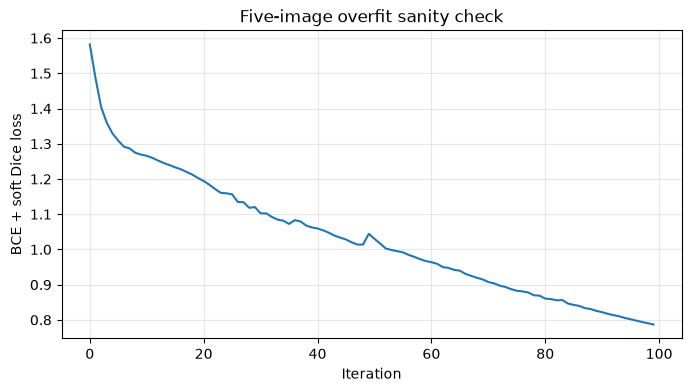

In [5]:

import copy
import torch
from torch import nn

# Fresh model so the sanity check starts from random initialization.
sanity_model = UNet().to(DEVICE)

optimizer = torch.optim.AdamW(
    sanity_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

bce_loss_fn = nn.BCEWithLogitsLoss()

def soft_dice_loss(logits, targets, eps=1e-6):
    probs = torch.sigmoid(logits)
    intersection = (probs * targets).sum(dim=(1, 2, 3))
    denominator = probs.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))

    dice = (2 * intersection + eps) / (denominator + eps)
    return 1 - dice.mean()

def combined_loss(logits, targets):
    return bce_loss_fn(logits, targets) + soft_dice_loss(logits, targets)

sanity_history = []
best_loss = float("inf")
best_state = None

for step in range(1, 101):
    sanity_model.train()
    optimizer.zero_grad(set_to_none=True)

    logits = sanity_model(X_sanity)
    loss = combined_loss(logits, Y_sanity)

    loss.backward()
    optimizer.step()

    loss_value = loss.item()
    sanity_history.append(loss_value)

    if loss_value < best_loss:
        best_loss = loss_value
        best_state = copy.deepcopy(sanity_model.state_dict())

    if step == 1 or step % 10 == 0:
        print(f"Step {step:3d}/100 | Loss: {loss_value:.4f}")

sanity_model.load_state_dict(best_state)

print("\nInitial loss:", round(sanity_history[0], 4))
print("Final loss:", round(sanity_history[-1], 4))
print("Best loss:", round(best_loss, 4))
print("Loss decreased:", best_loss < sanity_history[0])

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(sanity_history)
plt.xlabel("Iteration")
plt.ylabel("BCE + soft Dice loss")
plt.title("Five-image overfit sanity check")
plt.grid(True, alpha=0.3)
plt.show()


In [10]:

from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import random
import torch


CROP_HEIGHT = 256
CROP_WIDTH = 512


class SteelDefectDataset(Dataset):
    def __init__(self, image_ids, training=False):
        self.image_ids = list(image_ids)
        self.training = training

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        image, mask = load_image_and_mask(image_id)

        # Images are 256 x 1600. Keep the original resolution.
        if image.shape[:2] != (256, 1600):
            raise ValueError(
                f"Unexpected image shape for {image_id}: {image.shape}"
            )

        # Crop a 256 x 512 window.
        max_left = image.shape[1] - CROP_WIDTH

        if self.training:
            # Try a few crops to avoid selecting only background.
            # If none contains defects, use the final sampled crop.
            left = random.randint(0, max_left)

            for _ in range(8):
                candidate_left = random.randint(0, max_left)
                candidate_mask = mask[
                    :, candidate_left:candidate_left + CROP_WIDTH
                ]

                left = candidate_left

                if candidate_mask.any():
                    break
        else:
            # Deterministic center crop for validation.
            left = max_left // 2

        image = image[:, left:left + CROP_WIDTH, :]
        mask = mask[:, left:left + CROP_WIDTH]

        # Convert to float tensors.
        image_tensor = torch.from_numpy(
            image.astype(np.float32).copy() / 255.0
        ).permute(2, 0, 1)

        mask_tensor = torch.from_numpy(
            mask.astype(np.float32).copy()
        ).unsqueeze(0)

        # Simple paired augmentation: horizontal flip.
        if self.training and random.random() < 0.5:
            image_tensor = torch.flip(image_tensor, dims=[2])
            mask_tensor = torch.flip(mask_tensor, dims=[2])

        return image_tensor, mask_tensor, image_id


train_dataset = SteelDefectDataset(S1, training=True)
dev_dataset = SteelDefectDataset(DEV, training=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

# Verify shapes and binary masks.
images, masks, image_ids = next(iter(train_loader))
dev_images, dev_masks, dev_ids = next(iter(dev_loader))

print("Training images:", len(train_dataset))
print("Development images:", len(dev_dataset))
print("Training batch:", tuple(images.shape), tuple(masks.shape))
print("Validation batch:", tuple(dev_images.shape), tuple(dev_masks.shape))
print("Training mask values:", torch.unique(masks).tolist())
print("Validation mask values:", torch.unique(dev_masks).tolist())
print("Training defect pixels per crop:",
      masks.sum(dim=(1, 2, 3)).int().tolist())


Training images: 50
Development images: 200
Training batch: (2, 3, 256, 512) (2, 1, 256, 512)
Validation batch: (2, 3, 256, 512) (2, 1, 256, 512)
Training mask values: [0.0, 1.0]
Validation mask values: [0.0]
Training defect pixels per crop: [1384, 23751]


In [11]:

class FullWidthValidationDataset(Dataset):
    """Cover each 1600-pixel image with three 512-pixel crops."""

    def __init__(self, image_ids):
        self.image_ids = list(image_ids)
        self.crop_starts = [0, 512, 1088]

    def __len__(self):
        return len(self.image_ids) * len(self.crop_starts)

    def __getitem__(self, idx):
        image_idx = idx // len(self.crop_starts)
        crop_idx = idx % len(self.crop_starts)

        image_id = self.image_ids[image_idx]
        image, mask = load_image_and_mask(image_id)

        left = self.crop_starts[crop_idx]
        image = image[:, left:left + CROP_WIDTH, :]
        mask = mask[:, left:left + CROP_WIDTH]

        image_tensor = torch.from_numpy(
            image.astype(np.float32).copy() / 255.0
        ).permute(2, 0, 1)

        mask_tensor = torch.from_numpy(
            mask.astype(np.float32).copy()
        ).unsqueeze(0)

        return image_tensor, mask_tensor, image_id, left


dev_dataset = FullWidthValidationDataset(DEV)

dev_loader = DataLoader(
    dev_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

# Verify coverage using the first validation image.
crop_masks = [
    dev_dataset[i][1]
    for i in range(3)
]

print("Validation crops per image:", len(crop_masks))
print("Crop shapes:", [tuple(m.shape) for m in crop_masks])
print("Defect pixels per crop:", [int(m.sum()) for m in crop_masks])
print("Total defect pixels across crops:", sum(int(m.sum()) for m in crop_masks))


Validation crops per image: 3
Crop shapes: [(1, 256, 512), (1, 256, 512), (1, 256, 512)]
Defect pixels per crop: [0, 0, 0]
Total defect pixels across crops: 0


In [12]:

# Check complete masks, not just individual crops.
defect_present_count = 0
defect_free_count = 0

for image_id in DEV:
    _, full_mask = load_image_and_mask(image_id)

    if full_mask.any():
        defect_present_count += 1
    else:
        defect_free_count += 1

print("Full validation images:")
print("Defect-present:", defect_present_count)
print("Defect-free:", defect_free_count)

print("\nFirst five validation images:")
for image_id in DEV[:5]:
    _, full_mask = load_image_and_mask(image_id)
    print(
        image_id,
        "| full-image defect pixels:", int(full_mask.sum()),
    )


Full validation images:
Defect-present: 100
Defect-free: 100

First five validation images:
006a4402e.jpg | full-image defect pixels: 0
02d006f47.jpg | full-image defect pixels: 0
0429258ad.jpg | full-image defect pixels: 1412
07cbfd1f8.jpg | full-image defect pixels: 120096
0817e2da4.jpg | full-image defect pixels: 41526


In [17]:

import torch
import numpy as np

def evaluate_full_width(model, image_ids, threshold=0.5):
    model.eval()

    # Four overlapping crops cover the entire 1600-pixel width.
    crop_starts = (0, 363, 726, 1088)
    dice_scores = []
    iou_scores = []
    details = []

    with torch.no_grad():
        for image_id in image_ids:
            image, gt_mask = load_image_and_mask(image_id)

            probability_sum = np.zeros((256, 1600), dtype=np.float32)
            count_sum = np.zeros((256, 1600), dtype=np.float32)

            for left in crop_starts:
                crop = image[:, left:left + 512, :]
                crop_tensor = (
                    torch.from_numpy(crop.astype(np.float32).copy() / 255.0)
                    .permute(2, 0, 1)
                    .unsqueeze(0)
                    .to(DEVICE)
                )

                logits = model(crop_tensor)
                probs = torch.sigmoid(logits)[0, 0].cpu().numpy()

                probability_sum[:, left:left + 512] += probs
                count_sum[:, left:left + 512] += 1

            probabilities = probability_sum / np.maximum(count_sum, 1)
            pred_mask = probabilities >= threshold

            intersection = np.logical_and(pred_mask, gt_mask).sum()
            pred_pixels = pred_mask.sum()
            gt_pixels = gt_mask.sum()
            union = np.logical_or(pred_mask, gt_mask).sum()

            dice = (
                2 * intersection / (pred_pixels + gt_pixels)
                if pred_pixels + gt_pixels > 0 else 1.0
            )
            iou = intersection / union if union > 0 else 1.0

            dice_scores.append(dice)
            iou_scores.append(iou)
            details.append({
                "ImageId": image_id,
                "Dice": dice,
                "IoU": iou,
                "GT_pixels": int(gt_pixels),
                "Pred_pixels": int(pred_pixels),
            })

    return {
        "mean_dice": float(np.mean(dice_scores)),
        "mean_iou": float(np.mean(iou_scores)),
        "details": details,
    }


full_dev_metrics = evaluate_full_width(model, DEV)

print("Full-width development evaluation")
print("Images:", len(full_dev_metrics["details"]))
print("Mean image Dice:", round(full_dev_metrics["mean_dice"], 4))
print("Mean image IoU:", round(full_dev_metrics["mean_iou"], 4))
print("Mean GT pixels:", round(np.mean([
    x["GT_pixels"] for x in full_dev_metrics["details"]
])))
print("Mean predicted pixels:", round(np.mean([
    x["Pred_pixels"] for x in full_dev_metrics["details"]
])))

Full-width development evaluation
Images: 200
Mean image Dice: 0.2017
Mean image IoU: 0.1433
Mean GT pixels: 15030
Mean predicted pixels: 19564


Epoch 01/10 | Train loss: 1.4469 | Dev loss: 1.3248 | Dev Dice: 0.5000 | Dev IoU: 0.5000
Epoch 02/10 | Train loss: 1.2971 | Dev loss: 1.2777 | Dev Dice: 0.3688 | Dev IoU: 0.3672
Epoch 03/10 | Train loss: 1.2122 | Dev loss: 1.6280 | Dev Dice: 0.2043 | Dev IoU: 0.1421
Epoch 04/10 | Train loss: 1.1528 | Dev loss: 1.2939 | Dev Dice: 0.2241 | Dev IoU: 0.1611
Epoch 05/10 | Train loss: 1.1111 | Dev loss: 1.3679 | Dev Dice: 0.2236 | Dev IoU: 0.1580
Epoch 06/10 | Train loss: 1.0392 | Dev loss: 1.1392 | Dev Dice: 0.2092 | Dev IoU: 0.1505
Epoch 07/10 | Train loss: 1.0185 | Dev loss: 1.1429 | Dev Dice: 0.2304 | Dev IoU: 0.1635
Epoch 08/10 | Train loss: 0.9893 | Dev loss: 1.2493 | Dev Dice: 0.2136 | Dev IoU: 0.1464
Epoch 09/10 | Train loss: 0.9637 | Dev loss: 2.2594 | Dev Dice: 0.0957 | Dev IoU: 0.0598
Epoch 10/10 | Train loss: 0.9295 | Dev loss: 1.1258 | Dev Dice: 0.2531 | Dev IoU: 0.1886

Training time: 0.88 minutes
Best development loss: 1.1258
Checkpoint saved: E:\SAM\checkpoints\unet_baseline_

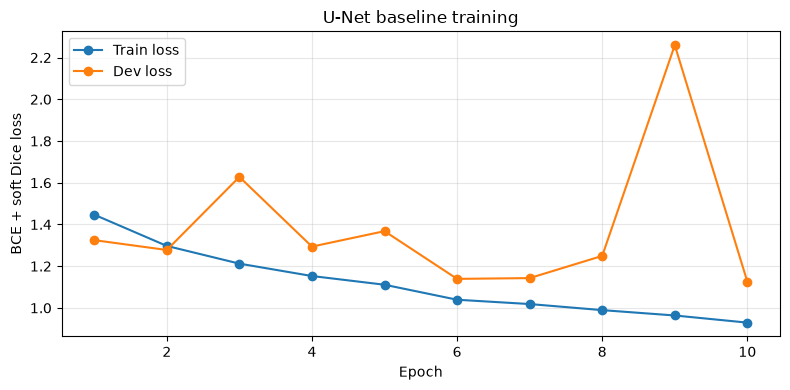

In [7]:

import copy
import json
import time
import torch
import matplotlib.pyplot as plt
from pathlib import Path

# Reproducibility
SEED = 532
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Fresh model for the full 50-image experiment.
model = UNet().to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

bce_loss_fn = torch.nn.BCEWithLogitsLoss()

def dice_iou_from_logits(logits, targets, threshold=0.5, eps=1e-7):
    probs = torch.sigmoid(logits)
    predictions = probs >= threshold
    targets = targets >= 0.5

    dims = (1, 2, 3)
    intersection = (predictions & targets).sum(dim=dims).float()
    pred_sum = predictions.sum(dim=dims).float()
    target_sum = targets.sum(dim=dims).float()
    union = pred_sum + target_sum - intersection

    dice = (2 * intersection + eps) / (pred_sum + target_sum + eps)
    iou = (intersection + eps) / (union + eps)
    return dice.mean().item(), iou.mean().item()

def evaluate(model, loader):
    model.eval()
    losses, dices, ious = [], [], []

    with torch.no_grad():
        for images, masks, _ in loader:
            images = images.to(DEVICE, non_blocking=True)
            masks = masks.to(DEVICE, non_blocking=True)

            logits = model(images)
            loss = combined_loss(logits, masks)

            dice, iou = dice_iou_from_logits(logits, masks)
            losses.append(loss.item())
            dices.append(dice)
            ious.append(iou)

    return {
        "loss": sum(losses) / len(losses),
        "dice": sum(dices) / len(dices),
        "iou": sum(ious) / len(ious),
    }

EPOCHS = 10
history = []
best_dev_loss = float("inf")
best_model_state = None

start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_losses = []

    for images, masks, _ in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        masks = masks.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = combined_loss(logits, masks)

        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    dev_metrics = evaluate(model, dev_loader)
    train_loss = sum(train_losses) / len(train_losses)

    record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "dev_loss": dev_metrics["loss"],
        "dev_dice": dev_metrics["dice"],
        "dev_iou": dev_metrics["iou"],
    }
    history.append(record)

    if dev_metrics["loss"] < best_dev_loss:
        best_dev_loss = dev_metrics["loss"]
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Dev loss: {dev_metrics['loss']:.4f} | "
        f"Dev Dice: {dev_metrics['dice']:.4f} | "
        f"Dev IoU: {dev_metrics['iou']:.4f}"
    )

elapsed = time.time() - start_time

# Restore best checkpoint in memory.
model.load_state_dict(best_model_state)

print(f"\nTraining time: {elapsed / 60:.2f} minutes")
print("Best development loss:", round(best_dev_loss, 4))

# Save checkpoint and history.
checkpoint_path = CHECKPOINT_DIR / "unet_baseline_best.pth"
history_path = OUTPUT_DIR / "unet_baseline_history.json"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "seed": SEED,
        "epochs": EPOCHS,
        "input_size": [256, 512],
        "training_ids": list(S1),
        "dev_ids": list(DEV),
        "best_dev_loss": best_dev_loss,
    },
    checkpoint_path,
)

with open(history_path, "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

print("Checkpoint saved:", checkpoint_path)
print("History saved:", history_path)

# Plot losses.
plt.figure(figsize=(8, 4))
plt.plot(
    [r["epoch"] for r in history],
    [r["train_loss"] for r in history],
    marker="o",
    label="Train loss",
)
plt.plot(
    [r["epoch"] for r in history],
    [r["dev_loss"] for r in history],
    marker="o",
    label="Dev loss",
)
plt.xlabel("Epoch")
plt.ylabel("BCE + soft Dice loss")
plt.title("U-Net baseline training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:

import torch
import numpy as np

# Evaluate the currently loaded best model over the complete dev set.
model.eval()

intersection_total = 0
prediction_total = 0
target_total = 0
per_image_dice = []
per_image_iou = []

with torch.no_grad():
    for images, masks, _ in dev_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        logits = model(images)
        predictions = torch.sigmoid(logits) >= 0.5
        targets = masks >= 0.5

        dims = (1, 2, 3)
        intersection = (predictions & targets).sum(dim=dims).float()
        pred_sum = predictions.sum(dim=dims).float()
        target_sum = targets.sum(dim=dims).float()
        union = pred_sum + target_sum - intersection

        dice = (2 * intersection + 1e-7) / (
            pred_sum + target_sum + 1e-7
        )
        iou = (intersection + 1e-7) / (union + 1e-7)

        per_image_dice.extend(dice.cpu().tolist())
        per_image_iou.extend(iou.cpu().tolist())

        intersection_total += intersection.sum().item()
        prediction_total += pred_sum.sum().item()
        target_total += target_sum.sum().item()

global_dice = (
    2 * intersection_total + 1e-7
) / (
    prediction_total + target_total + 1e-7
)

global_iou = (
    intersection_total + 1e-7
) / (
    prediction_total + target_total - intersection_total + 1e-7
)

print("Images evaluated:", len(per_image_dice))
print("Mean image Dice:", round(float(np.mean(per_image_dice)), 4))
print("Mean image IoU:", round(float(np.mean(per_image_iou)), 4))
print("Global pixel Dice:", round(global_dice, 4))
print("Global pixel IoU:", round(global_iou, 4))
print("Mean predicted-positive pixels:", round(prediction_total / len(DEV)))
print("Mean ground-truth-positive pixels:", round(target_total / len(DEV)))
print("Empty predictions:", sum(v == 0 for v in [
    # Count images with no predicted foreground.
]))


Images evaluated: 200
Mean image Dice: 0.2531
Mean image IoU: 0.1886
Global pixel Dice: 0.2584
Global pixel IoU: 0.1484
Mean predicted-positive pixels: 10410
Mean ground-truth-positive pixels: 4810
Empty predictions: 0


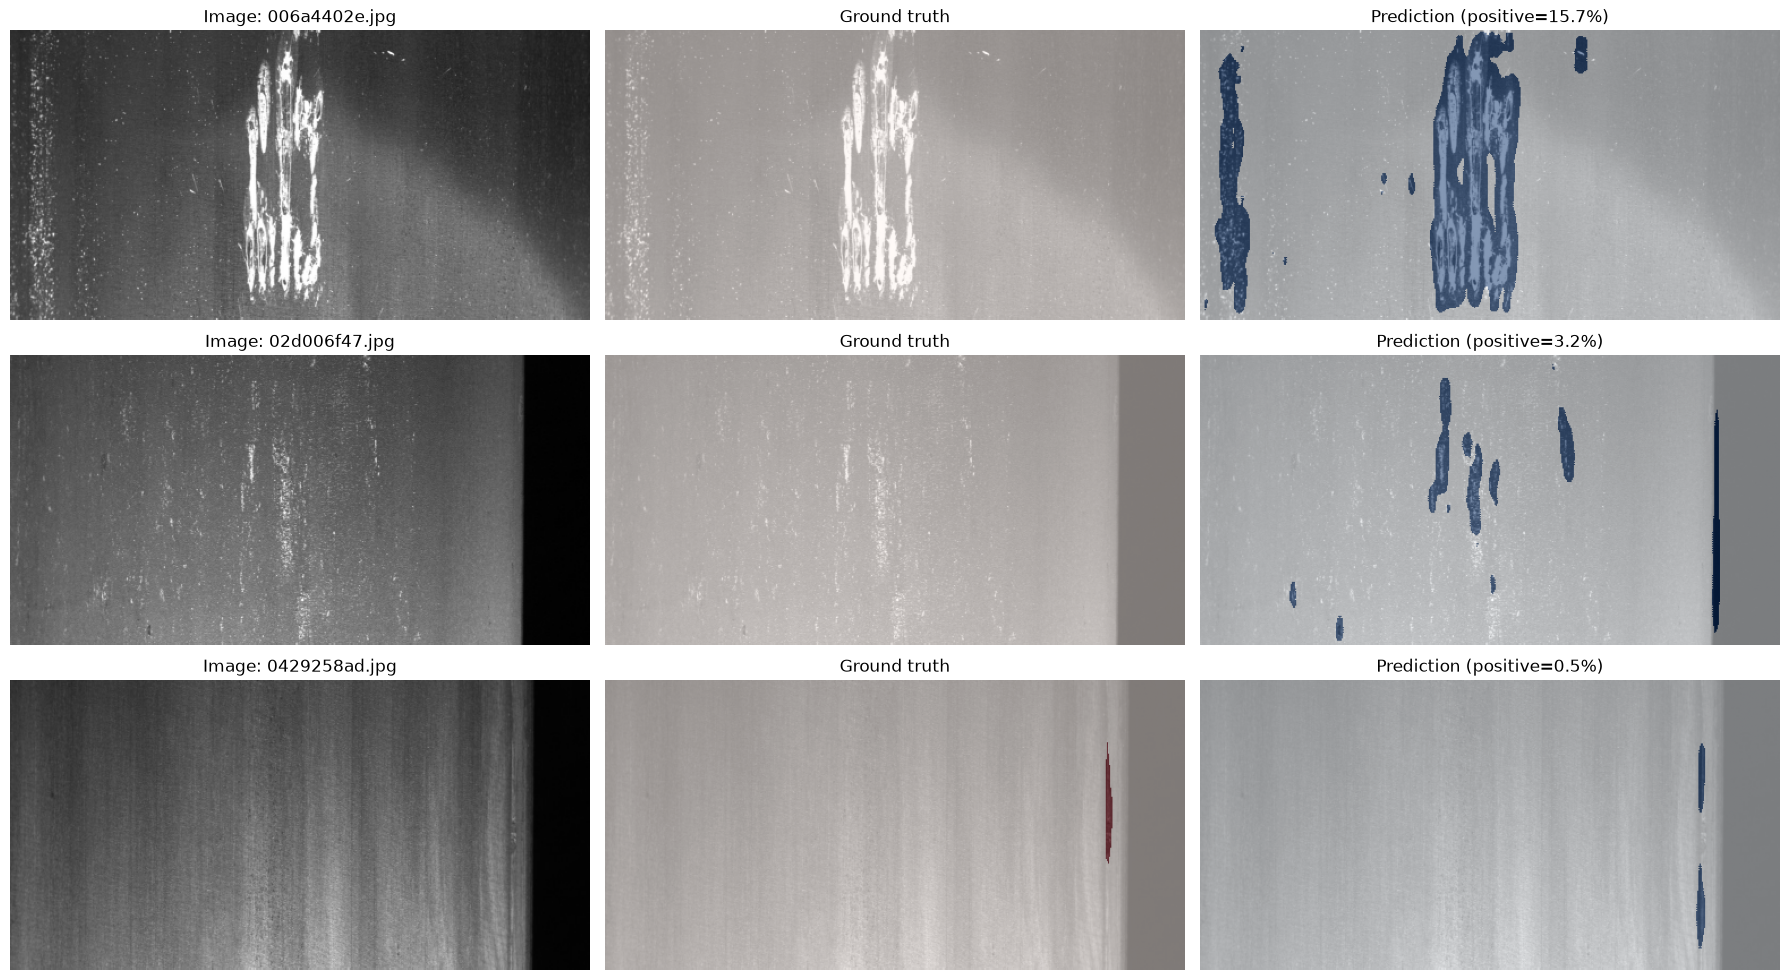

In [9]:

import matplotlib.pyplot as plt
import numpy as np
import torch

model.eval()

# Inspect three fixed development images.
visualization_ids = DEV[:3]

fig, axes = plt.subplots(3, 3, figsize=(18, 10))

with torch.no_grad():
    for row, image_id in enumerate(visualization_ids):
        image, true_mask = load_image_and_mask(image_id)

        # Apply the same preprocessing used for validation.
        resized_image = Image.fromarray(image).resize(
            (512, 256), Image.Resampling.BILINEAR
        )
        image_array = (
            np.asarray(resized_image, dtype=np.float32).copy() / 255.0
        )
        image_tensor = torch.from_numpy(image_array).permute(2, 0, 1)

        logits = model(image_tensor.unsqueeze(0).to(DEVICE))
        probability = torch.sigmoid(logits)[0, 0].cpu().numpy()
        predicted_mask = (probability >= 0.5).astype(np.uint8)

        true_resized = np.asarray(
            Image.fromarray(true_mask).resize(
                (512, 256), Image.Resampling.NEAREST
            ),
            dtype=np.uint8,
        )

        axes[row, 0].imshow(resized_image)
        axes[row, 0].set_title(f"Image: {image_id}")

        axes[row, 1].imshow(resized_image)
        axes[row, 1].imshow(true_resized, cmap="Reds", alpha=0.5)
        axes[row, 1].set_title("Ground truth")

        axes[row, 2].imshow(resized_image)
        axes[row, 2].imshow(predicted_mask, cmap="Blues", alpha=0.5)
        axes[row, 2].set_title(
            f"Prediction (positive={predicted_mask.mean():.1%})"
        )

        for ax in axes[row]:
            ax.axis("off")

plt.tight_layout()
plt.show()


In [18]:
import time
import json
import torch
from torch.optim import AdamW

torch.manual_seed(532)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(532)

model_crop = UNet().to(DEVICE)
optimizer = AdamW(
    model_crop.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

EPOCHS = 20
best_dev_dice = -1.0
history_crop = []

start_time = time.time()

for epoch in range(EPOCHS):
    model_crop.train()
    train_losses = []

    for images, masks, _ in train_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        logits = model_crop(images)
        loss = combined_loss(logits, masks)
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    # Validate using full-width, overlapping-crop inference.
    dev_metrics = evaluate_full_width(model_crop, DEV)

    train_loss = sum(train_losses) / len(train_losses)
    dev_dice = dev_metrics["mean_dice"]
    dev_iou = dev_metrics["mean_iou"]

    history_crop.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "dev_dice": dev_dice,
        "dev_iou": dev_iou,
    })

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Dev Dice: {dev_dice:.4f} | "
        f"Dev IoU: {dev_iou:.4f}"
    )

    if dev_dice > best_dev_dice:
        best_dev_dice = dev_dice
        torch.save(
            model_crop.state_dict(),
            CHECKPOINT_DIR / "unet_baseline_crops_best.pth"
        )

with open(OUTPUT_DIR / "unet_baseline_crops_history.json", "w") as f:
    json.dump(history_crop, f, indent=2)

print(f"\nTraining time: {(time.time() - start_time) / 60:.2f} minutes")
print(f"Best development Dice: {best_dev_dice:.4f}")
print("Crop-trained checkpoint and history saved.")

Epoch 01/20 | Train loss: 1.4387 | Dev Dice: 0.4869 | Dev IoU: 0.4861
Epoch 02/20 | Train loss: 1.2662 | Dev Dice: 0.2347 | Dev IoU: 0.2196
Epoch 03/20 | Train loss: 1.1793 | Dev Dice: 0.2283 | Dev IoU: 0.1642
Epoch 04/20 | Train loss: 1.1126 | Dev Dice: 0.2248 | Dev IoU: 0.1605
Epoch 05/20 | Train loss: 1.0690 | Dev Dice: 0.2442 | Dev IoU: 0.1813
Epoch 06/20 | Train loss: 1.0258 | Dev Dice: 0.2063 | Dev IoU: 0.1487
Epoch 07/20 | Train loss: 0.9932 | Dev Dice: 0.2600 | Dev IoU: 0.1912
Epoch 08/20 | Train loss: 0.9380 | Dev Dice: 0.1542 | Dev IoU: 0.1027
Epoch 09/20 | Train loss: 0.9294 | Dev Dice: 0.2616 | Dev IoU: 0.1917
Epoch 10/20 | Train loss: 0.8547 | Dev Dice: 0.1704 | Dev IoU: 0.1228
Epoch 11/20 | Train loss: 0.8916 | Dev Dice: 0.2107 | Dev IoU: 0.1512
Epoch 12/20 | Train loss: 0.8367 | Dev Dice: 0.2260 | Dev IoU: 0.1660
Epoch 13/20 | Train loss: 0.8675 | Dev Dice: 0.2622 | Dev IoU: 0.1909
Epoch 14/20 | Train loss: 0.8692 | Dev Dice: 0.2117 | Dev IoU: 0.1514
Epoch 15/20 | Train 

In [19]:
# Load the checkpoint selected by development Dice.
best_model = UNet().to(DEVICE)
checkpoint_path = CHECKPOINT_DIR / "unet_baseline_crops_best.pth"

best_model.load_state_dict(
    torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
)
best_model.eval()

best_metrics = evaluate_full_width(best_model, DEV)

print("Best checkpoint evaluation")
print("Mean Dice:", round(best_metrics["mean_dice"], 4))
print("Mean IoU:", round(best_metrics["mean_iou"], 4))
print("Mean GT pixels:", round(
    np.mean([x["GT_pixels"] for x in best_metrics["details"]])
))
print("Mean predicted pixels:", round(
    np.mean([x["Pred_pixels"] for x in best_metrics["details"]])
))

print("\nFirst 10 development images:")
for item in best_metrics["details"][:10]:
    print(
        item["ImageId"],
        "| Dice:", round(item["Dice"], 3),
        "| IoU:", round(item["IoU"], 3),
        "| GT:", item["GT_pixels"],
        "| Pred:", item["Pred_pixels"]
    )

Best checkpoint evaluation
Mean Dice: 0.4869
Mean IoU: 0.4861
Mean GT pixels: 15030
Mean predicted pixels: 81

First 10 development images:
006a4402e.jpg | Dice: 1.0 | IoU: 1.0 | GT: 0 | Pred: 0
02d006f47.jpg | Dice: 1.0 | IoU: 1.0 | GT: 0 | Pred: 0
0429258ad.jpg | Dice: 0.0 | IoU: 0.0 | GT: 1412 | Pred: 0
07cbfd1f8.jpg | Dice: 0.0 | IoU: 0.0 | GT: 120096 | Pred: 0
0817e2da4.jpg | Dice: 0.0 | IoU: 0.0 | GT: 41526 | Pred: 0
09e15218c.jpg | Dice: 0.0 | IoU: 0.0 | GT: 59788 | Pred: 0
0b475b419.jpg | Dice: 0.0 | IoU: 0.0 | GT: 3425 | Pred: 0
0f74501fa.jpg | Dice: 1.0 | IoU: 1.0 | GT: 0 | Pred: 0
0fab4b372.jpg | Dice: 1.0 | IoU: 1.0 | GT: 0 | Pred: 0
11bf761dc.jpg | Dice: 0.0 | IoU: 0.0 | GT: 19199 | Pred: 0


In [20]:
# Compare the training history.
print("Epoch | Train Loss | All-image Dice | All-image IoU")

for item in history_crop:
    print(
        f"{item['epoch']:>5} | "
        f"{item['train_loss']:.4f} | "
        f"{item['dev_dice']:.4f} | "
        f"{item['dev_iou']:.4f}"
    )

# Show the best epoch by the existing all-image Dice metric.
best_epoch = max(history_crop, key=lambda x: x["dev_dice"])
print("\nBest epoch by all-image Dice:", best_epoch["epoch"])

Epoch | Train Loss | All-image Dice | All-image IoU
    1 | 1.4387 | 0.4869 | 0.4861
    2 | 1.2662 | 0.2347 | 0.2196
    3 | 1.1793 | 0.2283 | 0.1642
    4 | 1.1126 | 0.2248 | 0.1605
    5 | 1.0690 | 0.2442 | 0.1813
    6 | 1.0258 | 0.2063 | 0.1487
    7 | 0.9932 | 0.2600 | 0.1912
    8 | 0.9380 | 0.1542 | 0.1027
    9 | 0.9294 | 0.2616 | 0.1917
   10 | 0.8547 | 0.1704 | 0.1228
   11 | 0.8916 | 0.2107 | 0.1512
   12 | 0.8367 | 0.2260 | 0.1660
   13 | 0.8675 | 0.2622 | 0.1909
   14 | 0.8692 | 0.2117 | 0.1514
   15 | 0.8733 | 0.2693 | 0.1981
   16 | 0.7786 | 0.1757 | 0.1267
   17 | 0.7647 | 0.2730 | 0.2037
   18 | 0.7739 | 0.2659 | 0.1962
   19 | 0.7822 | 0.2501 | 0.1903
   20 | 0.7412 | 0.2716 | 0.2011

Best epoch by all-image Dice: 1


In [21]:
# Evaluate the final in-memory model, not the Epoch 1 checkpoint.
final_metrics = evaluate_full_width(model_crop, DEV)

present = [x for x in final_metrics["details"] if x["GT_pixels"] > 0]
empty = [x for x in final_metrics["details"] if x["GT_pixels"] == 0]

print("FINAL EPOCH DIAGNOSTICS")
print("Defect-present images:", len(present))
print("Defect-free images:", len(empty))

print(
    "Mean Dice on defect-present images:",
    round(np.mean([x["Dice"] for x in present]), 4)
)
print(
    "Mean IoU on defect-present images:",
    round(np.mean([x["IoU"] for x in present]), 4)
)
print(
    "Mean predicted pixels on defect-present images:",
    round(np.mean([x["Pred_pixels"] for x in present]))
)
print(
    "Mean predicted pixels on defect-free images:",
    round(np.mean([x["Pred_pixels"] for x in empty]))
)

FINAL EPOCH DIAGNOSTICS
Defect-present images: 100
Defect-free images: 100
Mean Dice on defect-present images: 0.5032
Mean IoU on defect-present images: 0.3623
Mean predicted pixels on defect-present images: 32943
Mean predicted pixels on defect-free images: 56627


In [22]:
import numpy as np
import torch

def evaluate_thresholds(model, image_ids, thresholds=(0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9)):
    model.eval()
    crop_starts = (0, 363, 726, 1088)
    results = {t: {"present_dice": [], "empty_fp_pixels": []} for t in thresholds}

    with torch.no_grad():
        for image_id in image_ids:
            image, gt_mask = load_image_and_mask(image_id)
            probability_sum = np.zeros((256, 1600), dtype=np.float32)
            count_sum = np.zeros((256, 1600), dtype=np.float32)

            for left in crop_starts:
                crop = image[:, left:left + 512, :]
                x = (
                    torch.from_numpy(crop.astype(np.float32).copy() / 255.0)
                    .permute(2, 0, 1).unsqueeze(0).to(DEVICE)
                )
                probs = torch.sigmoid(model(x))[0, 0].cpu().numpy()
                probability_sum[:, left:left + 512] += probs
                count_sum[:, left:left + 512] += 1

            probs = probability_sum / np.maximum(count_sum, 1)
            gt_pixels = int(gt_mask.sum())

            for t in thresholds:
                pred = probs >= t
                pred_pixels = int(pred.sum())

                if gt_pixels > 0:
                    intersection = int(np.logical_and(pred, gt_mask).sum())
                    dice = 2 * intersection / max(pred_pixels + gt_pixels, 1)
                    results[t]["present_dice"].append(dice)
                else:
                    results[t]["empty_fp_pixels"].append(pred_pixels)

    for t in thresholds:
        print(
            f"Threshold {t:.1f} | "
            f"Defect-present Dice: {np.mean(results[t]['present_dice']):.4f} | "
            f"Mean FP pixels on empty images: "
            f"{np.mean(results[t]['empty_fp_pixels']):.0f}"
        )

evaluate_thresholds(model_crop, DEV)

Threshold 0.3 | Defect-present Dice: 0.4982 | Mean FP pixels on empty images: 64965
Threshold 0.4 | Defect-present Dice: 0.5018 | Mean FP pixels on empty images: 60545
Threshold 0.5 | Defect-present Dice: 0.5032 | Mean FP pixels on empty images: 56627
Threshold 0.6 | Defect-present Dice: 0.5034 | Mean FP pixels on empty images: 52872
Threshold 0.7 | Defect-present Dice: 0.5007 | Mean FP pixels on empty images: 48900
Threshold 0.8 | Defect-present Dice: 0.4914 | Mean FP pixels on empty images: 43129
Threshold 0.9 | Defect-present Dice: 0.4507 | Mean FP pixels on empty images: 34269


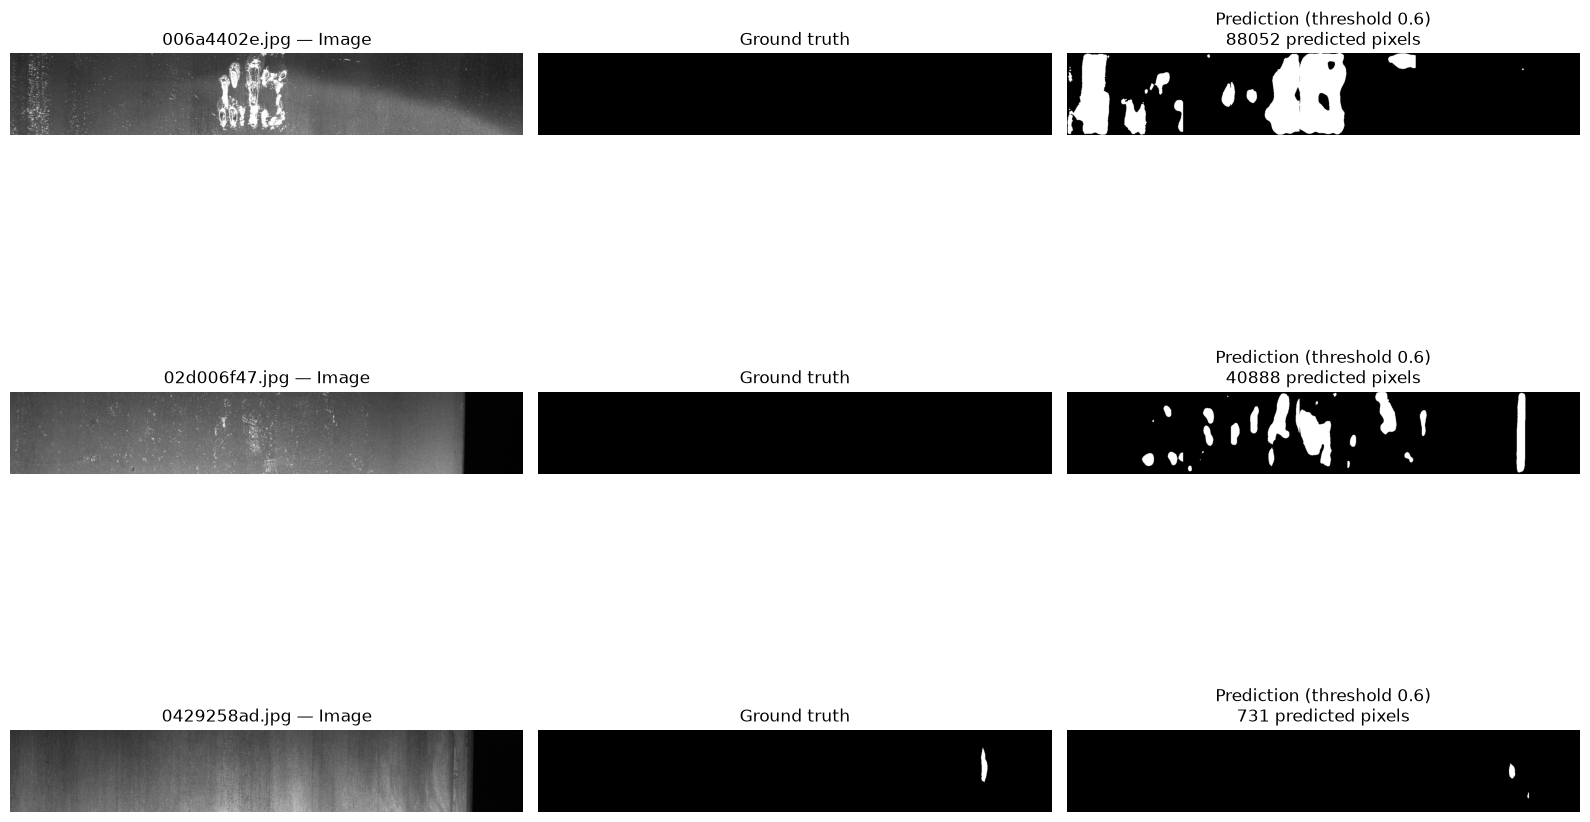

In [23]:
import matplotlib.pyplot as plt

# Two empty images and one defect-present image from DEV.
empty_ids = [
    x for x in DEV
    if not rles_by_image.get(x)
][:2]

present_ids = [
    x for x in DEV
    if rles_by_image.get(x)
][:1]

inspect_ids = empty_ids + present_ids

model_crop.eval()
fig, axes = plt.subplots(len(inspect_ids), 3, figsize=(16, 4 * len(inspect_ids)))

for row, image_id in enumerate(inspect_ids):
    image, gt_mask = load_image_and_mask(image_id)

    probability_sum = np.zeros((256, 1600), dtype=np.float32)
    count_sum = np.zeros((256, 1600), dtype=np.float32)

    with torch.no_grad():
        for left in (0, 363, 726, 1088):
            crop = image[:, left:left + 512, :]
            x = (
                torch.from_numpy(crop.astype(np.float32).copy() / 255.0)
                .permute(2, 0, 1).unsqueeze(0).to(DEVICE)
            )
            probs = torch.sigmoid(model_crop(x))[0, 0].cpu().numpy()
            probability_sum[:, left:left + 512] += probs
            count_sum[:, left:left + 512] += 1

    probs = probability_sum / np.maximum(count_sum, 1)
    pred_mask = probs >= 0.6

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{image_id} — Image")

    axes[row, 1].imshow(gt_mask, cmap="gray")
    axes[row, 1].set_title("Ground truth")

    axes[row, 2].imshow(pred_mask, cmap="gray")
    axes[row, 2].set_title(
        f"Prediction (threshold 0.6)\n{pred_mask.sum()} predicted pixels"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()